# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [1]:
import plotly.io as pio
pio.renderers.default = 'plotly_mimetype+notebook_connected+png'

import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Airbnb London Listings

df = pd.read_csv('../data/airbnb_london.csv')
print(f"Loaded: {len(df)} listings")
print(df.describe().round(1))


Loaded: 2500 listings
        price  minimum_nights  number_of_reviews  availability_365  \
count  2500.0          2500.0             2500.0            2500.0   
mean    148.6            14.8              147.9             183.7   
std     110.9             8.4               86.3             105.5   
min      20.5             1.0                0.0               0.0   
25%      71.7             8.0               74.0              92.0   
50%     117.5            15.0              145.0             182.0   
75%     188.9            22.0              222.2             277.0   
max    1032.4            29.0              299.0             364.0   

       reviews_per_month  
count             2500.0  
mean                 2.0  
std                  2.0  
min                  0.0  
25%                  0.6  
50%                  1.4  
75%                  2.8  
max                 15.2  


In [2]:
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95]
print(f"95th percentile price: £{p95:.0f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))


95th percentile price: £373
                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1251.0  176.3  75.7  28.0  119.6  163.4  223.5  372.6
Private room      942.0   87.3  39.5  20.9   59.0   78.6  106.0  277.9
Shared room       182.0   46.3  14.1  20.5   36.8   44.1   54.3   92.8


## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions

> 💡 `df_cap[df_cap['room_type'].isin(['Entire home/apt','Private room'])]`


                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1251.0  176.3  75.7  28.0  119.6  163.4  223.5  372.6
Private room      942.0   87.3  39.5  20.9   59.0   78.6  106.0  277.9
Median ratio: 2.1x, IQR ratio: 2.2x
Private rooms under £100: 70%


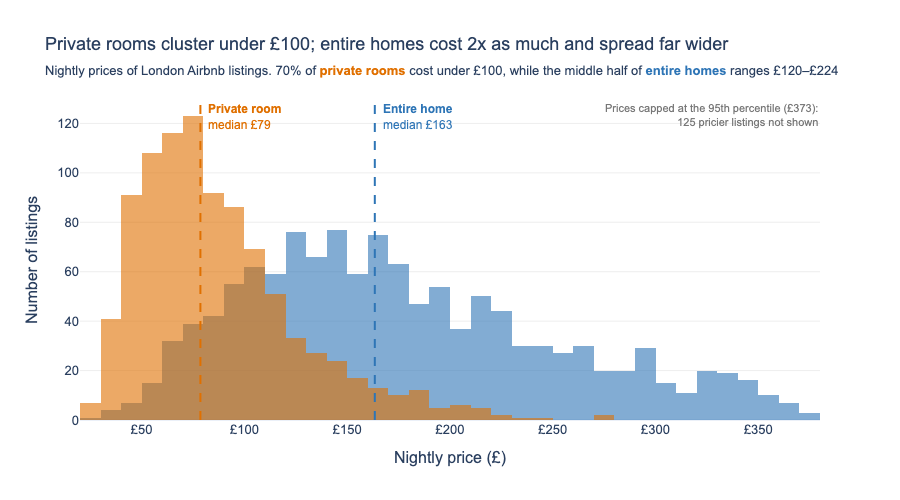

In [3]:
# Task 1 — price by room type, overlapping histograms
colors = {'Entire home/apt': '#2E75B6', 'Private room': '#E07000'}
data = df_cap[df_cap['room_type'].isin(colors)]

stats = data.groupby('room_type')['price'].describe()
medians = stats['50%']
iqr = stats['75%'] - stats['25%']
ratio = medians['Entire home/apt'] / medians['Private room']
private_under_100 = (data.loc[data['room_type'] == 'Private room', 'price'] < 100).mean()
n_capped = (df['price'] > p95).sum()
print(stats.round(1))
print(f"Median ratio: {ratio:.1f}x, IQR ratio: {iqr['Entire home/apt'] / iqr['Private room']:.1f}x")
print(f"Private rooms under £100: {private_under_100:.0%}")

fig = px.histogram(
    data_frame=data,
    x='price',
    color='room_type',
    color_discrete_map=colors,
    barmode='overlay',
    opacity=0.6,
    labels={'price': 'Nightly price (£)', 'room_type': 'Room type'},
    template='plotly_white',
    height=500, width=900
)

# same £10 bins for both room types so the bars line up
fig.update_traces(xbins=dict(start=0, end=p95, size=10), showlegend=False)

# median line per room type, labelled in its colour (doubles as the legend)
for room in colors:
    fig.add_vline(
        x=medians[room], line_dash='dash', line_color=colors[room], line_width=2,
        annotation=dict(
            text=f"<b>{room.replace('/apt', '')}</b><br>median £{medians[room]:.0f}",
            font=dict(color=colors[room], size=12),
            xanchor='left', yanchor='top', xshift=6, align='left'
        )
    )

fig.add_annotation(
    xref='paper', yref='paper', x=1, y=1, xanchor='right', yanchor='top',
    text=f"Prices capped at the 95th percentile (£{p95:.0f}):<br>{n_capped} pricier listings not shown",
    showarrow=False, align='right', font=dict(size=11, color='#777777')
)

fig.update_layout(
    title=dict(
        text=f"Private rooms cluster under £100; entire homes cost {ratio:.0f}x as much and spread far wider",
        subtitle=dict(text=(
            f"Nightly prices of London Airbnb listings. {private_under_100:.0%} of "
            f"<span style='color:{colors['Private room']}'><b>private rooms</b></span> cost under £100, while the middle half of "
            f"<span style='color:{colors['Entire home/apt']}'><b>entire homes</b></span> ranges "
            f"£{stats.loc['Entire home/apt', '25%']:.0f}–£{stats.loc['Entire home/apt', '75%']:.0f}"
        ))
    ),
    font=dict(family='Arial', size=13),
    xaxis=dict(showgrid=False, tickprefix='£'),
    yaxis=dict(gridcolor='#EEEEEE', title='Number of listings'),
    margin=dict(t=100)
)

fig.show()

## Task 2 — Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

Dropped 17 listings with no reviews
neighbourhood
Tower Hamlets             1.72
Hackney                   1.66
Camden                    1.58
Southwark                 1.50
Westminster               1.37
Lambeth                   1.32
Hammersmith               1.31
Kensington and Chelsea    1.26
Islington                 1.23
Wandsworth                1.07
Name: reviews_per_month, dtype: float64
All listings median: 1.43


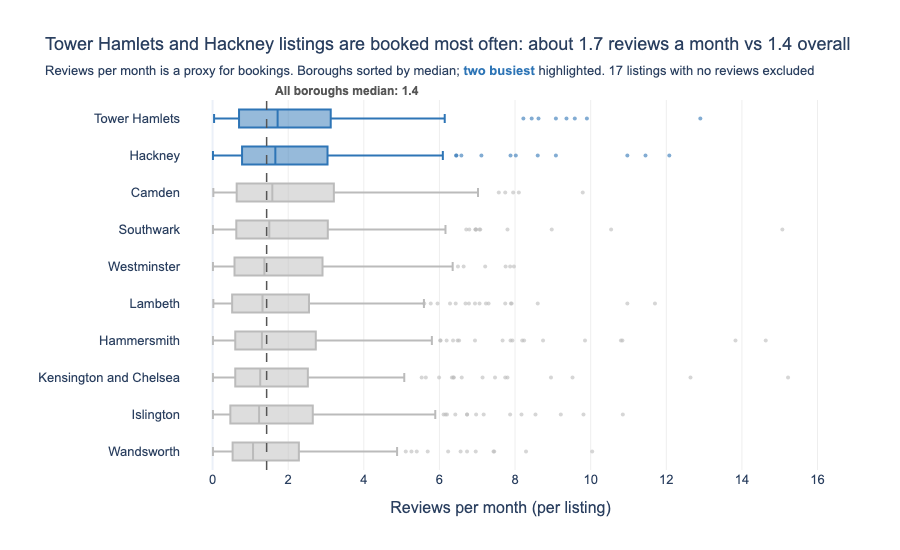

In [4]:
# Task 2 — reviews per month by borough, horizontal box plot
# reviews are not price, so this uses all listings (no price cap); listings with no review activity are dropped
active = df[(df['number_of_reviews'] > 0) & (df['reviews_per_month'] > 0)]
n_dropped = len(df) - len(active)

borough_median = active.groupby('neighbourhood')['reviews_per_month'].median().sort_values(ascending=False)
top2 = borough_median.index[:2].tolist()
top2_median = borough_median[top2].mean()
overall_median = active['reviews_per_month'].median()
print(f"Dropped {n_dropped} listings with no reviews")
print(borough_median.round(2))
print(f"All listings median: {overall_median:.2f}")

fig = px.box(
    data_frame=active,
    x='reviews_per_month',
    y='neighbourhood',
    color='neighbourhood',
    orientation='h',
    points='outliers',
    category_orders={'neighbourhood': borough_median.index.tolist()},
    color_discrete_map={b: '#2E75B6' if b in top2 else '#BBBBBB' for b in borough_median.index},
    labels={'reviews_per_month': 'Reviews per month (per listing)', 'neighbourhood': ''},
    template='plotly_white',
    height=550, width=900
)

fig.update_traces(marker=dict(size=4, opacity=0.6), showlegend=False)

fig.add_vline(
    x=overall_median, line_dash='dash', line_color='#555555', line_width=1.5,
    annotation=dict(
        text=f"<b>All boroughs median: {overall_median:.1f}</b>",
        font=dict(color='#555555', size=12),
        xanchor='left', yanchor='bottom', xshift=6
    )
)

fig.update_layout(
    title=dict(
        text=f"{top2[0]} and {top2[1]} listings are booked most often: "
             f"about {top2_median:.1f} reviews a month vs {overall_median:.1f} overall",
        subtitle=dict(text=(
            "Reviews per month is a proxy for bookings. Boroughs sorted by median; "
            f"<span style='color:#2E75B6'><b>two busiest</b></span> highlighted. "
            f"{n_dropped} listings with no reviews excluded"
        ))
    ),
    font=dict(family='Arial', size=13),
    boxmode='overlay',
    xaxis=dict(gridcolor='#EEEEEE'),
    yaxis=dict(showgrid=False),
    margin=dict(t=100)
)

fig.show()